# Graphicalizing a Scene Image

This notebook loads a local village landscape with houses, cars, and people, asks a vision-language model to describe the scene and locate foreground entities, analyzes saved region crops against the visual ontology, and extracts relations across the resulting graph. Install the optional dependency with `pip install -e '.[image]'`. Set `OPENAI_API_KEY` in the environment before running the model cell; the key is read by the OpenAI SDK and is never stored in this notebook.

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Image: office.png


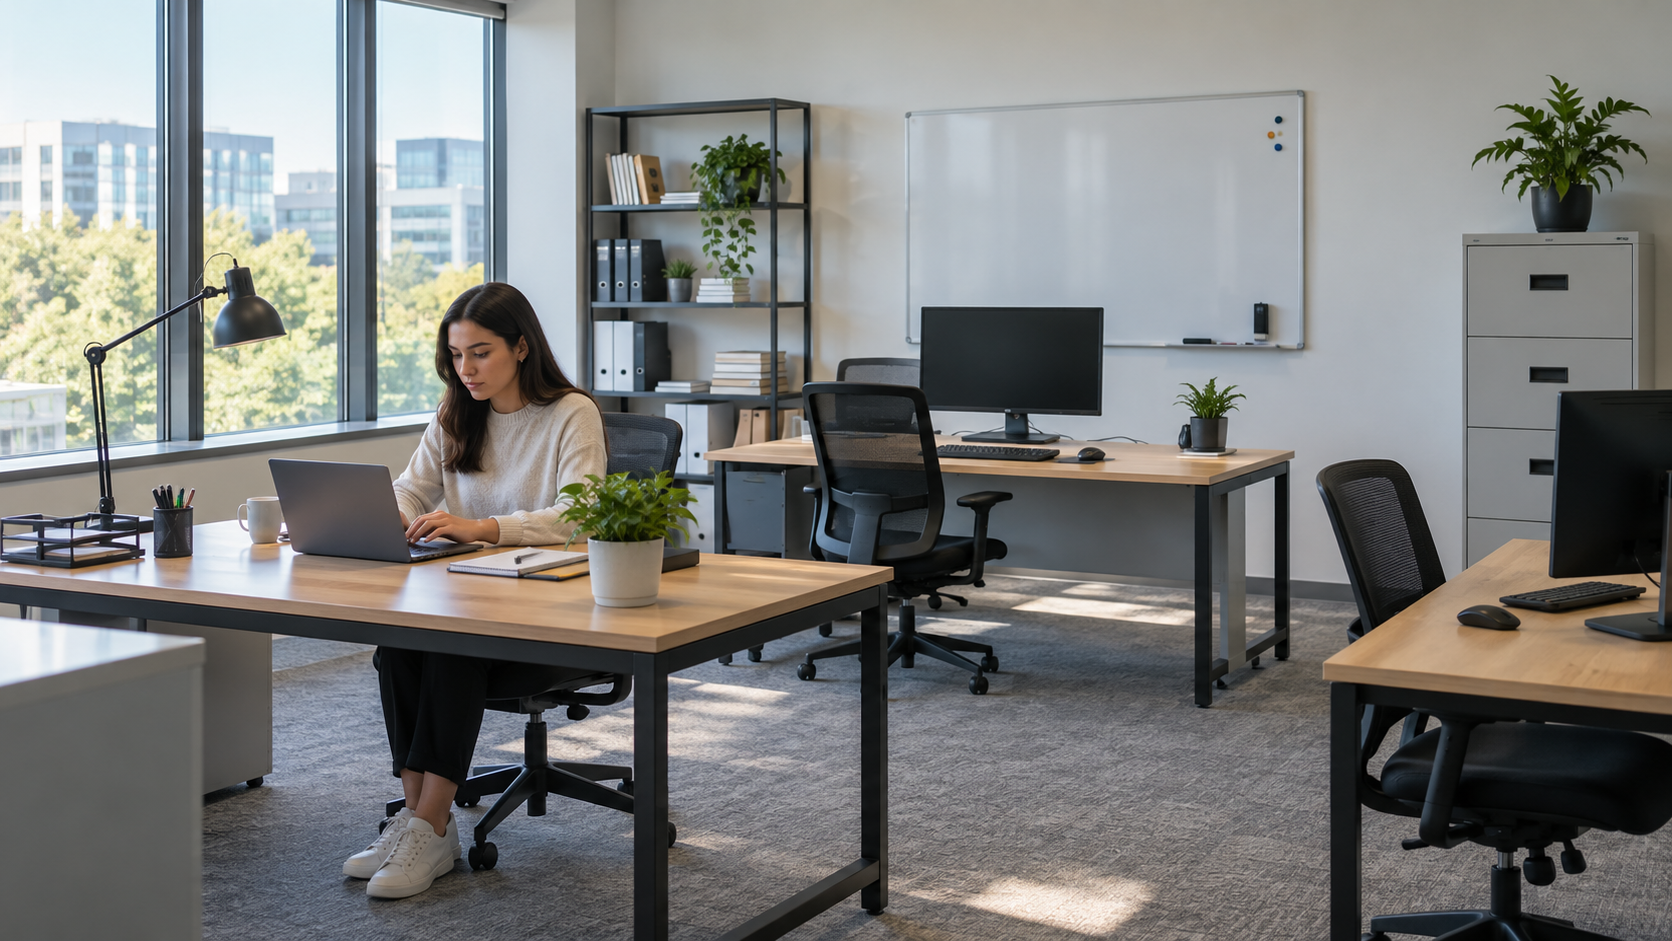

In [32]:
%config InlineBackend.figure_format = 'retina'

%load_ext autoreload
%autoreload 2

from pathlib import Path
from IPython.display import Image as DisplayImage, display

from semantic_graphicalizer import ImageGraphicalizer, display_graph

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
IMAGE_ROOT = ROOT / 'domains' / 'image'

image_path = IMAGE_ROOT / 'data' / 'raw' / 'office.png' # cat landscape office
if not image_path.is_file():
    raise FileNotFoundError(f'Add a local photograph at {image_path}')

print(f'Image: {image_path.name}')
display(DisplayImage(filename=str(image_path), width=900))

## OpenAI vision model

The image workflow defaults to `gpt-5.6-terra` through the Responses API. The workflow has three image-specific stages: whole-image scene inventory, per-crop ontology analysis, and document-level relation extraction. Region crops are saved under `domains/image/data/processed/regions/`.

In [33]:
graphicalizer = ImageGraphicalizer(
    ontology=IMAGE_ROOT / 'configs' / 'ontologies' / 'visual.yaml',
    prompts=IMAGE_ROOT / 'configs' / 'prompts' / 'scene_analysis.yaml',
    crop_dir=IMAGE_ROOT / 'data' / 'processed' / 'regions',
    verbose=True,
)

graphs = graphicalizer.transform(image_path)
graph = graphs[0]
print(f"ID: {graph.graph['document_id']}")
print(f"Scene: {graph.graph['scene_summary']}")
print(f"Regions: {len(graph.graph['parts'])} | Nodes: {graph.number_of_nodes()} | Edges: {graph.number_of_edges()}")

[ImageGraphicalizer] office.png: 22 regions, merged 6 duplicate detections, 44 nodes, 49 edges
ID: image-d3b2cb11bafe
Scene: Bright modern open-plan office with large windows overlooking nearby buildings and trees. A woman works at a laptop on the front desk; additional desks, chairs, monitors, a shelving unit, whiteboard, filing cabinet, plants, and desk accessories are visible.
Regions: 22 | Nodes: 44 | Edges: 49


In [34]:
scene_nodes = [node_id for node_id, data in graph.nodes(data=True) if data.get('type') == 'scene']

relation_nodes = [
    (node_id, data)
    for node_id, data in graph.nodes(data=True)
    if data.get('relation') is not None
]

print('Entities:')
for node_id, data in graph.nodes(data=True):
    if data.get('relation') is None:
        attributes = data.get('attributes', {})
        description = attributes.get('description', '')
        print(f"- {node_id}: {data['type']} — {description}")

print('\nRelations:')
for relation_id, data in relation_nodes:
    arguments = ', '.join(
        f"{edge.get('role')}={target}"
        for _source, target, edge in graph.out_edges(relation_id, data=True)
    )
    print(f"- {data['type']}[{data['relation']}]({arguments})")

print('\nGraph:')
display(display_graph(graph, mode='text', exclude_nodes=scene_nodes))

Entities:
- image-d3b2cb11bafe:scene: scene — Bright modern open-plan office with large windows overlooking nearby buildings and trees. A woman works at a laptop on the front desk; additional desks, chairs, monitors, a shelving unit, whiteboard, filing cabinet, plants, and desk accessories are visible.
- image-d3b2cb11bafe:entity:0:person_1:person_1: person — A woman with long dark hair sits in an office chair at a desk, looking at and typing on a laptop.
- image-d3b2cb11bafe:entity:0:person_1:laptop_1: laptop — An open dark gray laptop on the desk in front of the woman.
- image-d3b2cb11bafe:entity:2:desk_1:e1: desk — Large rectangular wood-top work desk with a black metal frame, viewed from the front and side.
- image-d3b2cb11bafe:entity:3:chair_1:chair_1: chair — Black ergonomic office chair, partially occluded by the seated woman and desk, with a mesh backrest, armrest, central pedestal, and five-wheel base.
- image-d3b2cb11bafe:entity:5:cup_1:e1: cup — A white ceramic mug with a sm

person: woman seated at a desk
    interacting_with: laptop: laptop being used by the woman; open laptop
    near: chair: office chair used by woman
laptop: laptop being used by the woman; open laptop
    contains: cup: white mug
    contains: document: spiral-bound notebook; loose paper
    contains: office_supply: pen
    contains: plant: potted plant
desk: front work desk
    contains: laptop: laptop being used by the woman; open laptop
    contains: cup: white mug
    contains: document: spiral-bound notebook; loose paper
    contains: office_supply: pen
    contains: plant: potted plant
cup: white mug
    contains: document: spiral-bound notebook; loose paper
    contains: office_supply: pen
    contains: plant: potted plant
    left_of: laptop: laptop being used by the woman; open laptop
document: spiral-bound notebook; loose paper
    contains: office_supply: pen
    contains: plant: potted plant
office_supply: pen
    contains: plant: potted plant
    near: document: spiral-bou

## Overlay the graph on the image

Entity nodes are anchored at the centers of their detected bounding boxes. Reified relation nodes are placed at the center of their argument entities, with argument edges drawn over the image. Whole-scene nodes and relations involving them are hidden by default to reduce clutter; pass `show_scene_nodes=True` to include them.

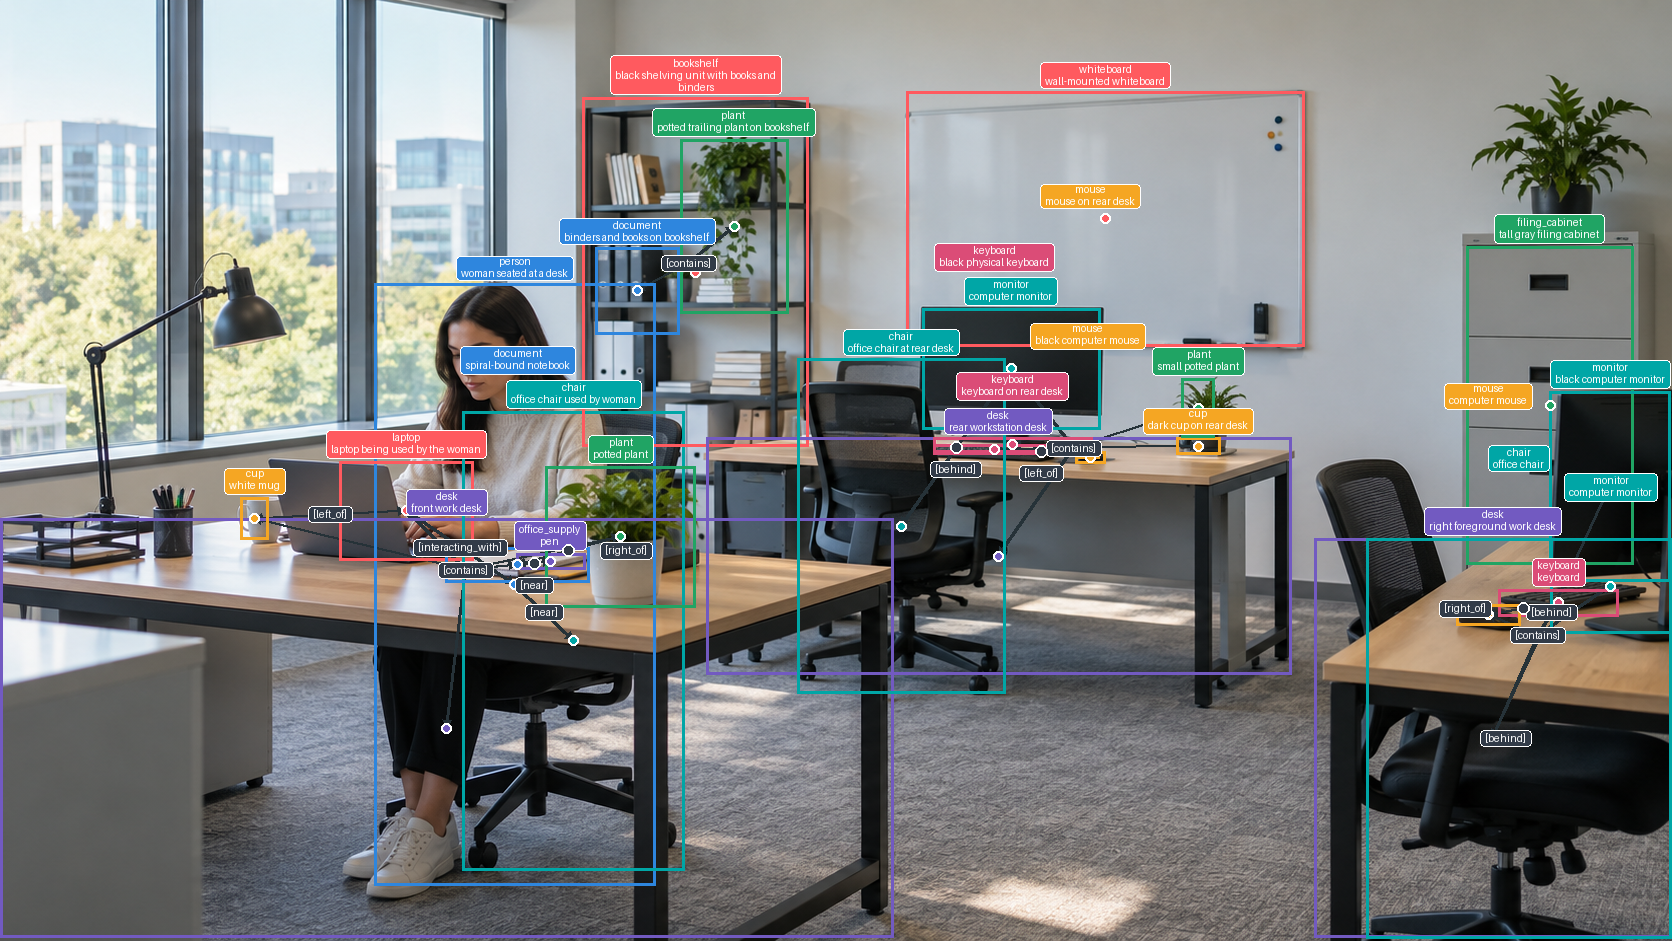

In [35]:
display(graphicalizer.display_on_image(graph, image=image_path))

In [38]:
display_graph(
    graph,
    mode='dynamic',
    exclude_nodes=scene_nodes,
    layout='force',
    show_relations_as_edges=True,
    show_source=True,
    max_width=34,
    width=1200,
    height=760,
    charge_strength=-10,
    link_distance=150,
    component_spacing=100,
    component_strength=0.3,
    parallel_edge_spacing=320,
)

## Inspect region crops and provenance

Each part records its source image, normalized bounding box, pixel bounding box, and saved crop path. Invalid or zero-area boxes are skipped and reported in `graph.graph['warnings']`.

image-d3b2cb11bafe:region:0:person_1
Box: [0.203, 0.297, 0.405, 0.952] (normalized)
Pixels: [339, 279, 678, 896]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/000-person_1.png


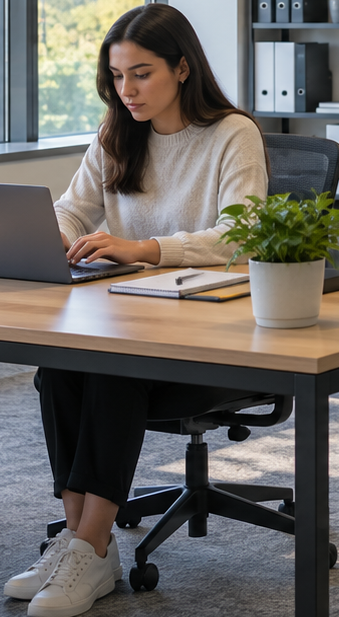

image-d3b2cb11bafe:region:1:laptop_1
Box: [0.16, 0.484, 0.273, 0.598] (normalized)
Pixels: [267, 455, 457, 563]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/001-laptop_1.png


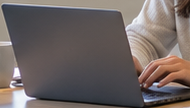

image-d3b2cb11bafe:region:2:desk_1
Box: [0.0, 0.533, 0.535, 0.997] (normalized)
Pixels: [0, 501, 895, 939]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/002-desk_1.png


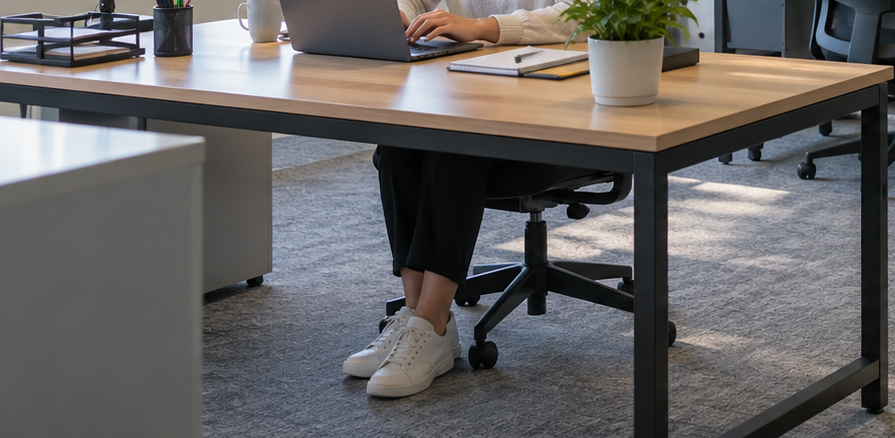

image-d3b2cb11bafe:region:3:chair_1
Box: [0.231, 0.431, 0.41, 0.929] (normalized)
Pixels: [386, 405, 686, 875]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/003-chair_1.png


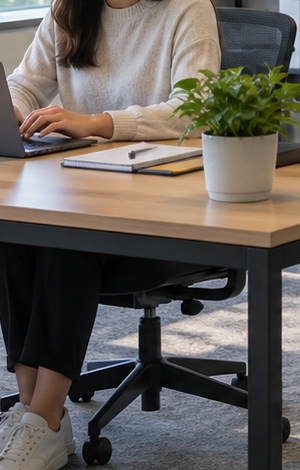

image-d3b2cb11bafe:region:5:cup_1
Box: [0.143, 0.527, 0.17, 0.575] (normalized)
Pixels: [239, 495, 285, 542]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/005-cup_1.png


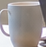

image-d3b2cb11bafe:region:7:document_1
Box: [0.266, 0.581, 0.353, 0.62] (normalized)
Pixels: [444, 546, 591, 584]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/007-document_1.png


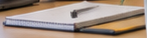

image-d3b2cb11bafe:region:8:plant_1
Box: [0.326, 0.495, 0.421, 0.646] (normalized)
Pixels: [545, 465, 704, 608]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/008-plant_1.png


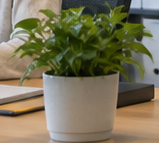

image-d3b2cb11bafe:region:9:shelf_1
Box: [0.348, 0.103, 0.484, 0.475] (normalized)
Pixels: [581, 96, 810, 447]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/009-shelf_1.png


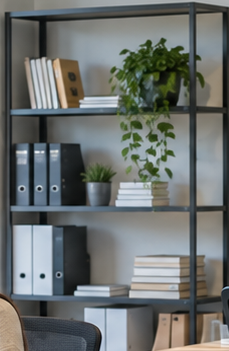

image-d3b2cb11bafe:region:10:plant_2
Box: [0.41, 0.14, 0.475, 0.326] (normalized)
Pixels: [685, 131, 795, 307]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/010-plant_2.png


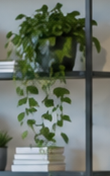

image-d3b2cb11bafe:region:11:whiteboard_1
Box: [0.54, 0.096, 0.8, 0.371] (normalized)
Pixels: [902, 90, 1338, 350]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/011-whiteboard_1.png


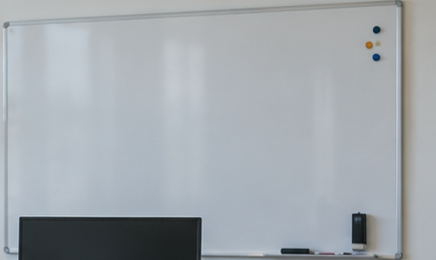

image-d3b2cb11bafe:region:12:desk_2
Box: [0.416, 0.464, 0.774, 0.753] (normalized)
Pixels: [695, 436, 1295, 709]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/012-desk_2.png


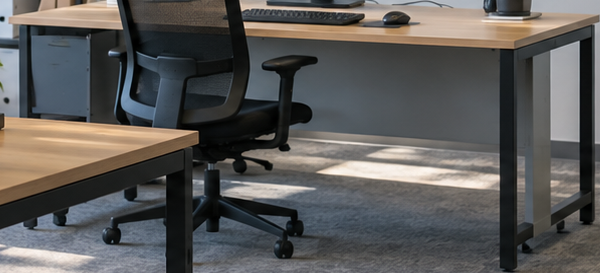

image-d3b2cb11bafe:region:13:monitor_1
Box: [0.55, 0.326, 0.66, 0.47] (normalized)
Pixels: [919, 306, 1104, 443]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/013-monitor_1.png


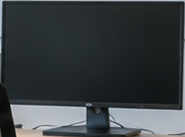

image-d3b2cb11bafe:region:14:keyboard_1
Box: [0.558, 0.467, 0.635, 0.49] (normalized)
Pixels: [932, 439, 1062, 462]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/014-keyboard_1.png


image-d3b2cb11bafe:region:15:mouse_1
Box: [0.644, 0.472, 0.662, 0.491] (normalized)
Pixels: [1076, 444, 1107, 463]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/015-mouse_1.png


image-d3b2cb11bafe:region:16:chair_2
Box: [0.474, 0.38, 0.604, 0.741] (normalized)
Pixels: [792, 357, 1010, 698]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/016-chair_2.png


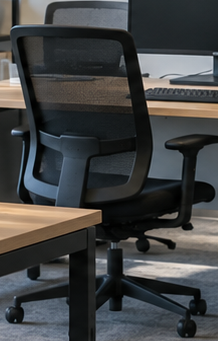

image-d3b2cb11bafe:region:17:plant_3
Box: [0.701, 0.402, 0.734, 0.483] (normalized)
Pixels: [1172, 378, 1228, 455]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/017-plant_3.png


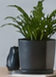

image-d3b2cb11bafe:region:18:filing_cabinet_1
Box: [0.873, 0.245, 0.979, 0.6] (normalized)
Pixels: [1459, 230, 1637, 565]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/018-filing_cabinet_1.png


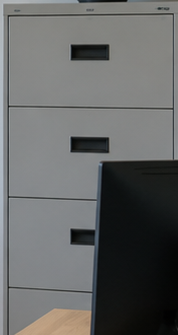

image-d3b2cb11bafe:region:20:desk_3
Box: [0.786, 0.572, 1.0, 0.998] (normalized)
Pixels: [1314, 538, 1672, 940]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/020-desk_3.png


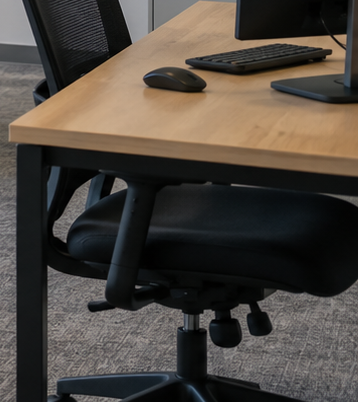

image-d3b2cb11bafe:region:21:monitor_2
Box: [0.925, 0.414, 1.0, 0.668] (normalized)
Pixels: [1546, 389, 1672, 629]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/021-monitor_2.png


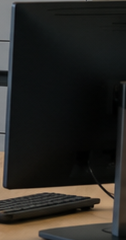

image-d3b2cb11bafe:region:22:keyboard_2
Box: [0.886, 0.62, 0.982, 0.654] (normalized)
Pixels: [1481, 583, 1642, 616]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/022-keyboard_2.png


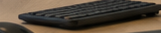

image-d3b2cb11bafe:region:23:mouse_2
Box: [0.87, 0.641, 0.91, 0.669] (normalized)
Pixels: [1454, 603, 1522, 630]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/023-mouse_2.png


image-d3b2cb11bafe:region:24:chair_3
Box: [0.802, 0.484, 1.0, 0.997] (normalized)
Pixels: [1340, 455, 1672, 939]
Crop: /Users/f.costa/Code/SemanticGraphicalizer/domains/image/data/processed/regions/image-d3b2cb11bafe/024-chair_3.png


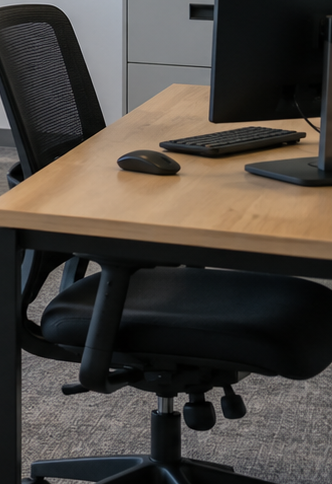

["region 'desk_lamp_1' skipped: bbox must have positive width and height",
 "region 'office_supply_1' skipped: bbox must have positive width and height",
 "region 'plant_4' skipped: bbox must have positive width and height"]

In [37]:
for part in graph.graph['parts']:
    print(part['part_id'])
    print(f"Box: {part['source_locator']['normalized_bbox']} (normalized)")
    print(f"Pixels: {part['source_locator']['pixel_bbox']}")
    print(f"Crop: {part['metadata']['crop_path']}")
    display(DisplayImage(filename=part['metadata']['crop_path'], width=360))

graph.graph['warnings']

## Embed the saved image parts

Install `pip install -e ".[image-embeddings]"` first. This opt-in step loads EmbeddingGemma 2 locally on its first call; this example requests a normalized 128-dimensional Matryoshka vector for each saved crop. Vectors are stored on the part records and entity provenance points to them through `part_id`.


In [ ]:
embedded_graphs = graphicalizer.compute_part_embeddings([graph], batch_size=16, embedding_dim=128)
for part in embedded_graphs[0].graph["parts"][:5]:
    print(part["part_id"], len(part["embedding"]), part["embedding_metadata"]["model"])
